In [1]:
import torch
import matplotlib.pyplot as plt
import numpy as np
import torch.nn as nn

In [2]:
class bsplines(nn.Module):

    def __init__(self, n_basis, degree, device):
        super().__init__()
        self.degree = degree
        self.n_basis = n_basis
        self.n_knots = n_basis + degree + 1
        # Uniform clamped bsplines
        knot_vector = torch.linspace(0, 10, self.n_knots - 2 * degree)
        self.knot_vector = torch.cat((
                torch.full((degree,), knot_vector[0]),
                knot_vector,
                torch.full((degree,), knot_vector[-1])
            ))
        
        # Same knot vector in every direction
        self.knot_x = self.knot_vector.clone()
        self.knot_y = self.knot_vector.clone()

        # 2D trainable coefficients
        self.coeffs = torch.zeros(n_basis, n_basis,device=device, requires_grad=True)

        self.raw_D = nn.Parameter(torch.tensor([0], dtype=torch.float32))  # initial guess
        self.softplus = nn.Softplus()
        # 2D input
        # self.x = x

        # Bsplines for the two dimensions
        
    def bspline_basis(self,i, p, x, knots):
        if p == 0:
            ###########Changes##################
            # return ((x >= knots[i]) & (x < knots[i+1])).float()
            return ((x >= knots[i]) & (x <= knots[i+1])).float()
            ###########Changes##################
        
        else:
            denom1 = knots[i+p] - knots[i]
            denom2 = knots[i+p+1] - knots[i+1]

            term1 = 0.0
            if denom1 > 0:
                term1 = (x - knots[i]) / denom1 * self.bspline_basis(i, p-1, x, knots)

            term2 = 0.0
            if denom2 > 0:
                term2 = (knots[i+p+1] - x) / denom2 * self.bspline_basis(i+1, p-1, x, knots)

            return term1 + term2

    def forward(self,x, device):

        self.B_x = torch.stack([self.bspline_basis(i, self.degree, x[:,0], self.knot_x ) for i in range(self.n_basis)])
        self.B_y = torch.stack([self.bspline_basis(j, self.degree, x[:,1], self.knot_y) for j in range(self.n_basis)])
        
        y = torch.zeros(x.shape[0], device=device)

        # Because we have Dirichlet BC we just omit the first and last bsplines. If we had BC we should put coeff*Bspline in a different loop 
        # they are not trainable parameteres trainable parameters.
        for i in range(1,(self.n_basis-1)):
            for j in range(1,(self.n_basis-1)):
                y += self.coeffs[i, j] * self.B_x[i]*self.B_y[j]
        

        return y
    
    def D(self):
        return self.softplus(self.raw_D)

    # send every attribute to device
    def to(self, device):
        for attr, value in self.__dict__.items():
            if isinstance(value, torch.Tensor):
                setattr(self, attr, value.to(device))

In [3]:
torch.manual_seed(42)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

In [4]:
torch.manual_seed(42)

model = bsplines(10,6,device)

In [5]:
model.to(device)

In [6]:
p_0 = 0.015
E   = 30000
h   =0.2
nu  =0.2

D   = E*h**3/(12*(1-nu**2))

a = b = 10

DC have already been imposed to zero. Now we want to impose Neuman boundary condition:

$m_x(x,y)=-D(\theta_x^2u+\nu\theta_y^2u)$
$\\ m_y(x,y)=-D(\nu\theta_x^2u+\theta_y^2u)$
$\\ m_x(0,y) = m_x(10,y)=m_y(x,0)=m_y(x,10)=0$

Train the interior points 
$\\ res = \nabla^4u(x,y)-\frac{p(x,y)}{D} = \theta^4w/\theta x^4+2\theta^4w/\theta x^2\theta y^2+\theta^4w/\theta y^4-\frac{p(x,y)}{D}$



In [7]:
def source(X):

    p = p_0*torch.sin(torch.pi*X[:,0]/a)*torch.sin(torch.pi*X[:,1]/b)

    return p

In [8]:
x = y = np.linspace(0, 10, 100)
Xg, Yg = np.meshgrid(x, y)
XY = np.vstack([Xg.ravel(), Yg.ravel()]).T
XY_torch = torch.tensor(XY, dtype=torch.float32)
XYt = XY_torch*0.999+0.0001




In [9]:
def u_exact(x,y, D, a, b, p_0):
    

    u_ex = p_0/(torch.pi**4*D*(1/a**2+1/b**2)**2)*torch.sin(x*torch.pi/a)*torch.sin(y*torch.pi/b)

    return u_ex


In [10]:
u_ex = u_exact(XYt[:,0], XYt[:,1], D, a, b, p_0)
u_ex=u_ex.to(device)

# noise = torch.normal(mean=0.0, std=0.05, size=u_ex.shape)
noise = torch.normal(mean=0.0, std=0.03, size=u_ex.shape)
noise = noise.to(device)
u_noisy = u_ex + noise

XYt = XYt.to(device)
XYt.requires_grad_(True)

tensor([[1.0000e-04, 1.0000e-04],
        [1.0101e-01, 1.0000e-04],
        [2.0192e-01, 1.0000e-04],
        ...,
        [9.7883e+00, 9.9901e+00],
        [9.8892e+00, 9.9901e+00],
        [9.9901e+00, 9.9901e+00]], device='cuda:0', requires_grad=True)

In [21]:
# Starts with 1e-2 without scalings and then reduced to 1e-3 to reduce oscillations and get better convergence.
learning_rate=1e-4
# torch.manual_seed(42)
optimizer = torch.optim.Adam([model_s.coeffs,model_s.raw_D], lr=learning_rate)


In [17]:
loss_vec=[]

In [32]:
# 500 for 1e-3 and 500 for 1e-4
# and more 500
epochs = 500


for epoch in range(epochs):
    
    optimizer.zero_grad()
    
    u = model_s.forward(XYt,device)
    # First derivatives
    grads = torch.autograd.grad(u, XYt, grad_outputs=torch.ones_like(u), create_graph=True)[0]
    u_x = grads[:, 0]
    u_y = grads[:, 1]

    # Second derivatives (Laplacian)
    grads2_x = torch.autograd.grad(u_x, XYt, grad_outputs=torch.ones_like(u_x), create_graph=True)[0]
    grads2_y = torch.autograd.grad(u_y, XYt, grad_outputs=torch.ones_like(u_y), create_graph=True)[0]

    u_xx = grads2_x[:, 0]
    u_xy = grads2_x[:, 1]
    u_yy = grads2_y[:, 1]
    u_yx = grads2_y[:, 0]  # should equal u_xy

    laplacian_u = u_xx + u_yy

    # Now compute ∇²(∇²u) = Laplacian of laplacian_u
    laplacian_u_grad = torch.autograd.grad(laplacian_u, XYt, grad_outputs=torch.ones_like(laplacian_u), create_graph=True)[0]
    laplacian_u_x = laplacian_u_grad[:, 0]
    laplacian_u_y = laplacian_u_grad[:, 1]

    laplacian_u_xx = torch.autograd.grad(laplacian_u_x, XYt, grad_outputs=torch.ones_like(laplacian_u_x), create_graph=True)[0][:, 0]
    laplacian_u_yy = torch.autograd.grad(laplacian_u_y, XYt, grad_outputs=torch.ones_like(laplacian_u_y), create_graph=True)[0][:, 1]

    p = source(XYt)

    Dt = model_s.D().to(device)
    # Residual loss
    res = laplacian_u_xx + laplacian_u_yy - p/Dt
    
    loss_res = torch.mean(res**2)

    loss_data=torch.mean((u - u_ex)**2)

    # normally is without scaling(the inverse without noise)
    loss = loss_res+loss_data
    
    loss.backward()
    
    # Manually update parameters using the gradients
    optimizer.step()
    loss_vec.append(loss.item())
    # Print loss and parameters every 100 iterations
    if (epoch + 1) % 5 == 0:
        D_est = Dt.item()
        print(f"Epoch {epoch:5d} | Loss: {loss.item():} | D: {D_est:}")

Epoch     4 | Loss: 1.3567486435543674e-13 | D: 20.828645706176758
Epoch     9 | Loss: 1.3470190132584825e-13 | D: 20.828645706176758
Epoch    14 | Loss: 1.3380606572830495e-13 | D: 20.828645706176758
Epoch    19 | Loss: 1.330397516327922e-13 | D: 20.828645706176758
Epoch    24 | Loss: 1.3235934700692176e-13 | D: 20.828645706176758
Epoch    29 | Loss: 1.3172998119832108e-13 | D: 20.828645706176758
Epoch    34 | Loss: 1.3113593327548911e-13 | D: 20.828645706176758
Epoch    39 | Loss: 1.3065180990042002e-13 | D: 20.828645706176758
Epoch    44 | Loss: 1.3014760168010564e-13 | D: 20.828645706176758
Epoch    49 | Loss: 1.297396028500722e-13 | D: 20.828645706176758
Epoch    54 | Loss: 1.2934522430983059e-13 | D: 20.828645706176758
Epoch    59 | Loss: 1.2901848643262492e-13 | D: 20.828645706176758
Epoch    64 | Loss: 1.287463381348039e-13 | D: 20.828645706176758
Epoch    69 | Loss: 1.2844757267364837e-13 | D: 20.828645706176758
Epoch    74 | Loss: 1.281943843613187e-13 | D: 20.828645706176758

In [24]:
# Save loss
loss_vec_npy = np.array(loss_vec)
np.save('./results/Kirchoff_inverse/bsplines_loss_ext.npy',loss_vec_npy)

In [23]:
#Save model trainable parameters
params = { 'coeffs_trainable': model_s.coeffs, 'D_trainable': model_s.raw_D}
torch.save(params, './results/Kirchoff_inverse/model_bsplines_ext.pth')

Table 10 bsplines

In [7]:
# Load model trainable parameters
model_s = bsplines(10,6,device)
loaded_params = torch.load('./results/Kirchoff_inverse/model_bsplines_ext.pth')
model_s.coeffs = loaded_params['coeffs_trainable']
model_s.raw_D = loaded_params['D_trainable']

C:\Users\Polydoras\AppData\Local\Temp\ipykernel_88248\2311733626.py:3: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  loaded_params = torch.load('./results/Kirchoff_inverse/m

In [8]:
model_s.D().item()

20.828645706176758

In [ ]:
model_s.D().item()

20.829069137573242

In [10]:
# 🔍 Evaluate on a test grid
x = y = torch.linspace(0, 1, 100)
Xg, Tg = torch.meshgrid(x, y)
Xg, Tg = Xg.to(device), Tg.to(device)
XY = torch.vstack([Xg.ravel(), Tg.ravel()]).T
XY_torch = torch.tensor(XY, dtype=torch.float32)
XY_torch = XY_torch.to(device)

# Prediction
with torch.no_grad():
    u_pred = model_s.forward(XY_torch,device).reshape(Xg.shape)

# ✅ Exact solution
u_exact = u_exact(Xg, Tg, D, a, b, p_0)

c:\Users\Polydoras\Documents\Sisc\PhD\PI_bsplines\.venv\lib\site-packages\torch\functional.py:513: UserWarning: torch.meshgrid: in an upcoming release, it will be required to pass the indexing argument. (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\builder\windows\pytorch\aten\src\ATen\native\TensorShape.cpp:3610.)
  return _VF.meshgrid(tensors, **kwargs)  # type: ignore[attr-defined]
C:\Users\Polydoras\AppData\Local\Temp\ipykernel_88248\1531885621.py:6: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  XY_torch = torch.tensor(XY, dtype=torch.float32)


In [11]:
re = torch.sqrt(torch.sum((u_pred - u_exact)**2))/torch.sqrt(torch.sum(u_exact**2))
re.item()


0.00013375944399740547

In [12]:
re_p=np.sqrt((model_s.D().item() - 20.83333)**2)/np.sqrt(20.83333**2)
re_p

0.00022484613949101337

In [13]:
# Load loss
loss_bsplines_s = np.load('./results/Kirchoff_inverse/bsplines_loss.npy')
loss_bsplines_s_ext = np.load('./results/Kirchoff_inverse/bsplines_loss_ext.npy')
loss_pinn = np.load('./results/Kirchoff_inverse/pinn_loss.npy')

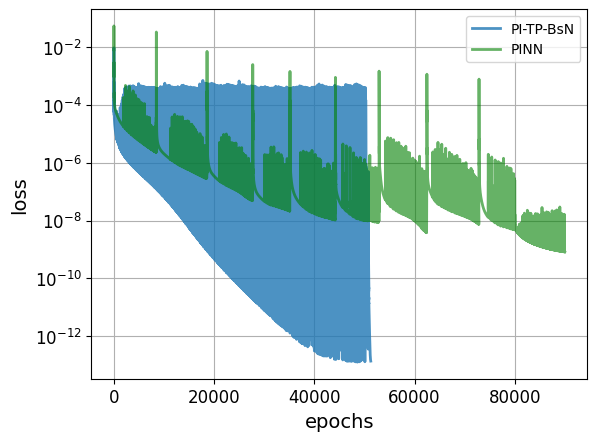

In [14]:
# THis is the loss Figure 16. In PI-TP-BsN we also added 1000 epochs with reduced learning rate to reduce the oscillations

x_a = np.arange(len(loss_bsplines_s)+len(loss_bsplines_s_ext))
x_b = np.arange(len(loss_pinn))
plt.plot(x_a, np.concatenate((loss_bsplines_s, loss_bsplines_s_ext)), label='PI-TP-BsN', alpha=0.8,linewidth=2)
plt.plot(x_b, loss_pinn, label='PINN', alpha=0.6, color='green',linewidth=2)
plt.legend()
plt.yscale('log')
# plt.title("Losses",fontsize=14)
plt.xlabel("epochs",fontsize=14)
plt.ylabel("loss",fontsize=14)
plt.tick_params(axis='both', labelsize=12)
plt.grid(True)

plt.savefig("loss_inv_kirch.pdf", dpi=300)
plt.show()

PINN Solution

In [1]:
import torch
import torch.nn as nn
import numpy as np
import matplotlib.pyplot as plt

In [2]:

torch.manual_seed(42)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Neural network model
class PINN(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(2, 96), nn.Tanh(),
            nn.Linear(96, 96), nn.Tanh(),
            nn.Linear(96, 96), nn.Tanh(),
            nn.Linear(96, 1)
        )
        self.raw_D = nn.Parameter(torch.tensor([0.1], dtype=torch.float32))  # initial guess
        self.softplus = nn.Softplus()

    def forward(self, x, t):
        return self.net(torch.cat([x, t], dim=1))

    def D(self):
        return self.softplus(self.raw_D)  # ensures positivity

In [3]:
# Initialize mod
model = PINN().to(device)


In [4]:
x = y = np.linspace(0, 10, 100)
# x = y = np.linspace(0, 10, 32)
Xg, Yg = np.meshgrid(x, y)
XY = np.vstack([Xg.ravel(), Yg.ravel()]).T
XY_torch = torch.tensor(XY, dtype=torch.float32)
XYt = XY_torch*0.999+0.0001

x = XYt[:,0].reshape(XYt.shape[0],1)
y = XYt[:,1].reshape(XYt.shape[0],1)
x = x.to(device)
y = y.to(device)

In [3]:
p_0 = 0.015
E   = 30000
h   =0.2
nu  =0.2

D   = E*h**3/(12*(1-nu**2))

a = b = 10

In [6]:
def source(x,y):

    p = p_0*torch.sin(torch.pi*x/a)*torch.sin(torch.pi*y/b)

    return p

In [4]:
def u_exact(x,y, D, a, b, p_0):
    

    u_ex = p_0/(torch.pi**4*D*(1/a**2+1/b**2)**2)*torch.sin(x*torch.pi/a)*torch.sin(y*torch.pi/b)

    return u_ex

u_ex = u_exact(x, y, D, a, b, p_0)
u_ex=u_ex.to(device)

# noise = torch.normal(mean=0.0, std=0.05, size=u_ex.shape)
noise = torch.normal(mean=0.0, std=0.03, size=u_ex.shape)
noise = noise.to(device)
u_noisy = u_ex + noise



# XYt.requires_grad_(True)


NameError: name 'x' is not defined

In [8]:
def biharmonic(model, x, y):
    """Compute Δ²u using autograd (u must depend on x, y)."""
    x.requires_grad_(True)
    y.requires_grad_(True)
    u = model(x, y)
    
    
    # First derivatives
    u_x = torch.autograd.grad(u, x, torch.ones_like(u), create_graph=True, retain_graph=True)[0]
    u_y = torch.autograd.grad(u, y, torch.ones_like(u), create_graph=True, retain_graph=True)[0]

    # Second derivatives
    u_xx = torch.autograd.grad(u_x, x, torch.ones_like(u_x), create_graph=True, retain_graph=True)[0]
    u_yy = torch.autograd.grad(u_y, y, torch.ones_like(u_y), create_graph=True, retain_graph=True)[0]

    # Laplacian
    lap_u = u_xx + u_yy

    # Derivatives of Laplacian
    lap_x = torch.autograd.grad(lap_u, x, torch.ones_like(lap_u), create_graph=True, retain_graph=True)[0]
    lap_y = torch.autograd.grad(lap_u, y, torch.ones_like(lap_u), create_graph=True, retain_graph=True)[0]

    #########################Here I delete retain_graph=True#########################
    lap_xx = torch.autograd.grad(lap_x, x, torch.ones_like(lap_x), create_graph=True)[0]
    lap_yy = torch.autograd.grad(lap_y, y, torch.ones_like(lap_y), create_graph=True)[0]

    p = source(x, y)
    Dt = model.D()

    res = lap_xx + lap_yy - p / Dt

    return res


In [12]:
optimizer = torch.optim.Adam(model.parameters(), lr=1e-4)

In [10]:
loss_vec = []

In [13]:
#After 80000 we reduce learning rate from 1e-3 to 1e-4 to 90000 epochs
epochs = 10000


for epoch in range(epochs):

    optimizer.zero_grad()
    
    # Forward pass
    u = model.forward(x, y)

    # Data loss
    loss_data = torch.mean((u - u_ex)**2)

    # PDE residual
    res= biharmonic(model, x, y)

    # PDE Loss
    loss_res = torch.mean(res**2)

    # Total loss
    loss = loss_res + loss_data

    # Backprop
    loss.backward()
    optimizer.step()


    loss_vec.append(loss.item())
    # Print loss and parameters every 100 iterations
    if (epoch + 1) % 1000 == 0:
        D_est = model.D().item()
        print(f"Epoch {epoch:5d} | Loss: {loss.item():} | D: {D_est:}")

Epoch   999 | Loss: 3.1218225782225772e-09 | D: 20.14320182800293
Epoch  1999 | Loss: 2.263848664085799e-09 | D: 20.14320182800293
Epoch  2999 | Loss: 1.7951407027538835e-09 | D: 20.14320182800293
Epoch  3999 | Loss: 1.6178856032667e-09 | D: 20.14320182800293
Epoch  4999 | Loss: 1.2922729553110912e-09 | D: 20.14320182800293
Epoch  5999 | Loss: 1.1421066314909467e-09 | D: 20.14320182800293
Epoch  6999 | Loss: 1.5674883613314705e-09 | D: 20.14320182800293
Epoch  7999 | Loss: 9.394686140140607e-10 | D: 20.14320182800293
Epoch  8999 | Loss: 1.3891585659564498e-08 | D: 20.14320182800293
Epoch  9999 | Loss: 8.161299969167146e-10 | D: 20.14320182800293


In [17]:
# Save loss
loss_vec_npy = np.array(loss_vec)
np.save('./results/Kirchoff_inverse/pinn_loss.npy',loss_vec_npy)

In [16]:
#Save model trainable parameters
torch.save(model.state_dict(), './results/Kirchoff_inverse/model_pinn.pth')

In [10]:
#Load pinn loss
pinn_loss_s = np.load('./results/Kirchoff_inverse/pinn_loss.npy')

Table 10 PINN

In [5]:
# Load trained model
model_s = PINN()
model_s.load_state_dict(torch.load('./results/Kirchoff_inverse/model_pinn.pth'))


C:\Users\Polydoras\AppData\Local\Temp\ipykernel_57068\3262569562.py:3: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  model_s.load_state_dict(torch.load('./results/Kirchoff_i

<All keys matched successfully>

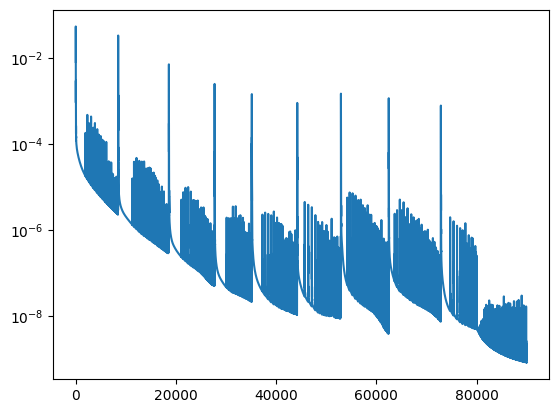

In [26]:
plt.plot(pinn_loss_s)
plt.yscale('log')

In [6]:
model_s.D().item()

20.14320182800293

In [7]:
# RE(D)
re_p=np.sqrt((model_s.D().item() - 20.83333)**2)/np.sqrt(20.83333**2)
re_p

0.03312615755604459

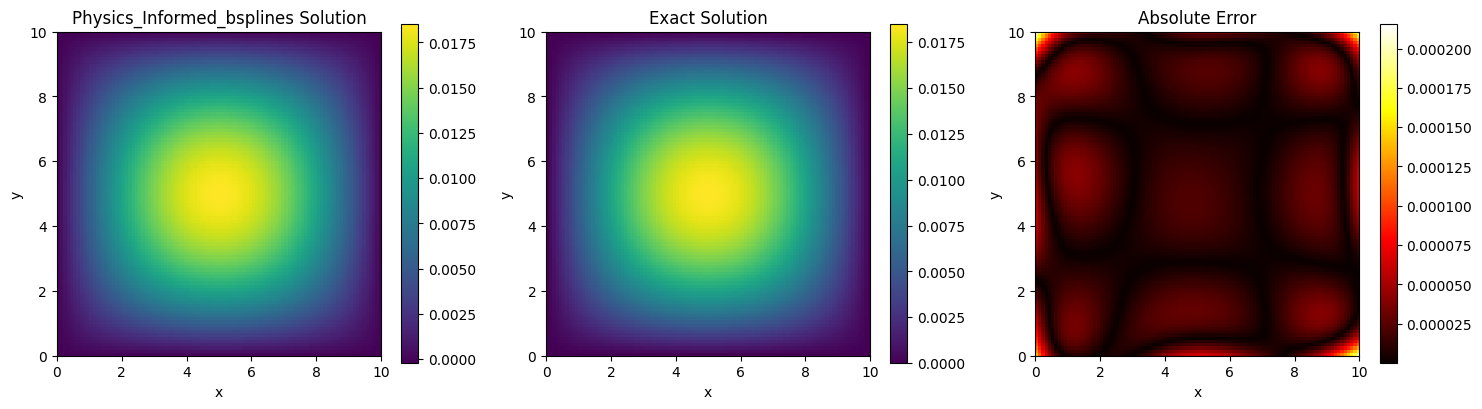

In [8]:
def u_exact(x,y, D, a, b, p_0):
    

    u_ex = p_0/(np.pi**4*D*(1/a**2+1/b**2)**2)*np.sin(x*np.pi/a)*np.sin(y*np.pi/b)

    return u_ex
x1 = y1 = np.linspace(0, 10, 100)
Xg1, Yg1 = np.meshgrid(x1, y1)
XY1 = np.vstack([Xg1.ravel(), Yg1.ravel()]).T
XY_torch1 = torch.tensor(XY1, dtype=torch.float32)
model_s.to('cpu')
with torch.no_grad():
    u_pred = model_s.forward(XY_torch1[:,0].reshape(XY_torch1.shape[0],1), XY_torch1[:,1].reshape(XY_torch1.shape[0],1)).numpy().reshape(Xg1.shape)
fig, axs = plt.subplots(1, 3, figsize=(15, 4))

# u_exact = np.sin(np.pi * Xg) * np.sin(np.pi * Yg)
u_ex = u_exact(Xg1, Yg1, D, a, b, p_0)

# PINN solution
im0 = axs[0].imshow(u_pred, extent=[0,10,0,10], origin='lower', cmap='viridis')
axs[0].set_title("Physics_Informed_bsplines Solution")
fig.colorbar(im0, ax=axs[0])

# Exact solution
im1 = axs[1].imshow(u_ex, extent=[0,10,0,10], origin='lower', cmap='viridis')
axs[1].set_title("Exact Solution")
fig.colorbar(im1, ax=axs[1])

# Absolute error
error = np.abs(u_pred - u_ex)
im2 = axs[2].imshow(error, extent=[0,10,0,10], origin='lower', cmap='hot')
axs[2].set_title("Absolute Error")
fig.colorbar(im2, ax=axs[2])

for ax in axs:
    ax.set_xlabel("x")
    ax.set_ylabel("y")

plt.tight_layout()
# plt.savefig('Kirchoff.pdf',dpi=300)
plt.show()

In [9]:
# RE(u)
re = np.sqrt(np.sum((u_pred - u_ex)**2))/np.sqrt(np.sum(u_ex**2))
re

0.002308368157138481